# Data Science Tool Mastery Project
### Yuva Internship — Practical Notebook

**Objective:** Practise essential Data Science tools using Python, NumPy, Pandas, Matplotlib, Seaborn, and Scikit-learn.

**Dataset:** Iris flower dataset, provided by Scikit-learn. It contains 150 flower samples, four numeric measurements, and three species classes.

**Instructions:** Run the cells from top to bottom. Outputs and charts will be generated when you run the notebook. Review the results and write observations based on your own run.

## 1. Import libraries and verify the environment

In [13]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
sns.set_theme(style="whitegrid")

Python: 3.14.6
NumPy: 2.4.6
Pandas: 3.0.3
Matplotlib: 3.11.0
Seaborn: 0.13.2
Scikit-learn: 1.9.0


## 2. NumPy numerical operations

In [14]:
values = np.array([12, 15, 18, 20, 25], dtype=float)
print("Array:", values)
print("Mean:", values.mean())
print("Standard deviation:", values.std())
print("Array multiplied by 2:", values * 2)

Array: [12. 15. 18. 20. 25.]
Mean: 18.0
Standard deviation: 4.427188724235731
Array multiplied by 2: [24. 30. 36. 40. 50.]


**Observation:** NumPy makes it easy to perform vectorized calculations and summary statistics on numeric arrays.

## 3. Load and inspect the Iris dataset

In [15]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=["target"])
feature_columns = list(iris.feature_names)

print("First five rows:")
display(df.head())
print("Dataset shape:", df.shape)
print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))
print("\nSummary statistics:")
display(df.describe().T)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Column data types:


,data_type
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
species,str



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 4. Pandas filtering and grouping

In [16]:
print("Number of rows per species:")
display(df["species"].value_counts().to_frame("count"))

print("Rows with petal length greater than 4.5 cm:")
display(df.loc[df["petal length (cm)"] > 4.5].head(10))

print("Average sepal length by species:")
display(df.groupby("species")["sepal length (cm)"].mean().to_frame("average_sepal_length"))

Number of rows per species:


,count
species,
setosa,50
versicolor,50
virginica,50


Rows with petal length greater than 4.5 cm:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
50,7.0,3.2,4.7,1.4,versicolor
52,6.9,3.1,4.9,1.5,versicolor
54,6.5,2.8,4.6,1.5,versicolor
56,6.3,3.3,4.7,1.6,versicolor
58,6.6,2.9,4.6,1.3,versicolor
63,6.1,2.9,4.7,1.4,versicolor
70,5.9,3.2,4.8,1.8,versicolor
72,6.3,2.5,4.9,1.5,versicolor
73,6.1,2.8,4.7,1.2,versicolor
76,6.8,2.8,4.8,1.4,versicolor


Average sepal length by species:


,average_sepal_length
species,
setosa,5.006
versicolor,5.936
virginica,6.588


## 5. Data-quality checks

In [17]:
missing_counts = df.isna().sum()
duplicate_count = int(df.duplicated().sum())

print("Missing values by column:")
display(missing_counts.to_frame("missing_count"))
print("Exact duplicate rows:", duplicate_count)

if missing_counts.sum() == 0 and duplicate_count == 0:
    print("No missing values or exact duplicate rows were detected.")
else:
    print("Review the counts and decide whether cleaning is required. Do not remove records automatically.")

Missing values by column:


,missing_count
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


Exact duplicate rows: 1
Review the counts and decide whether cleaning is required. Do not remove records automatically.


## 6. Visualize numeric distributions

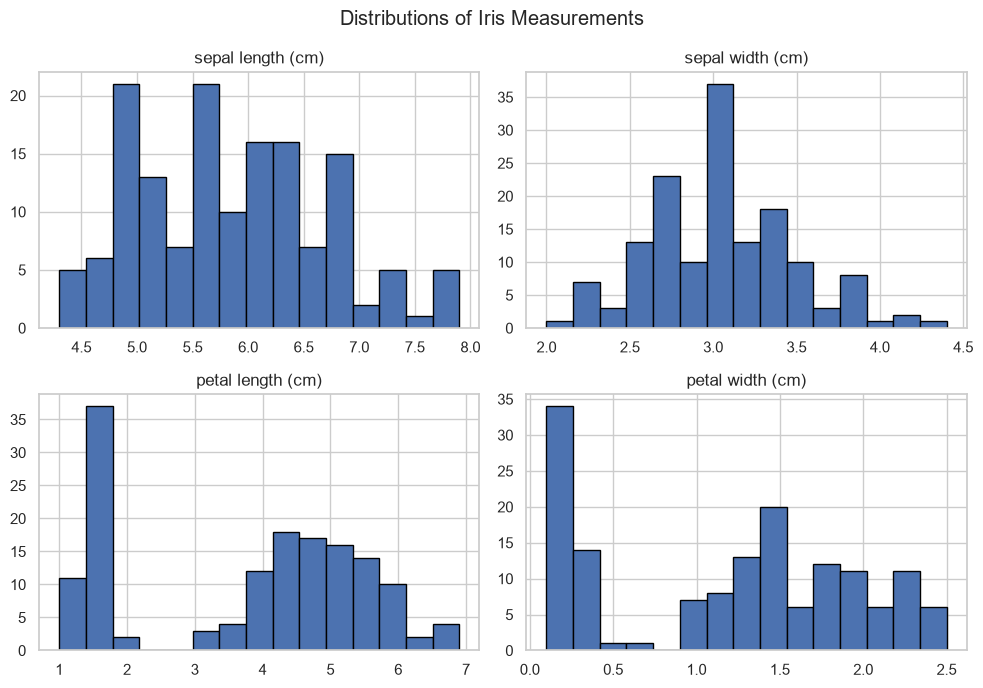

In [18]:
df[feature_columns].hist(figsize=(10, 7), bins=15, edgecolor="black")
plt.suptitle("Distributions of Iris Measurements")
plt.tight_layout()
plt.show()

**Observation prompt:** Identify which measurements show broad ranges or multiple clusters. A histogram describes distribution but does not establish causation.

## 7. Compare species using charts

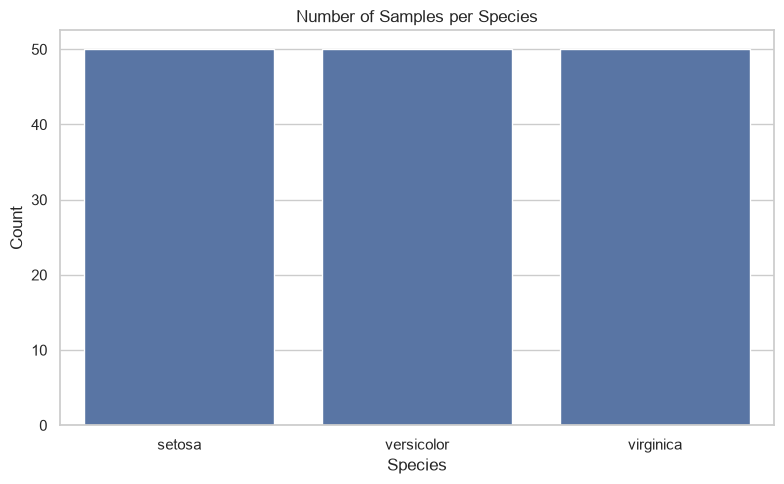

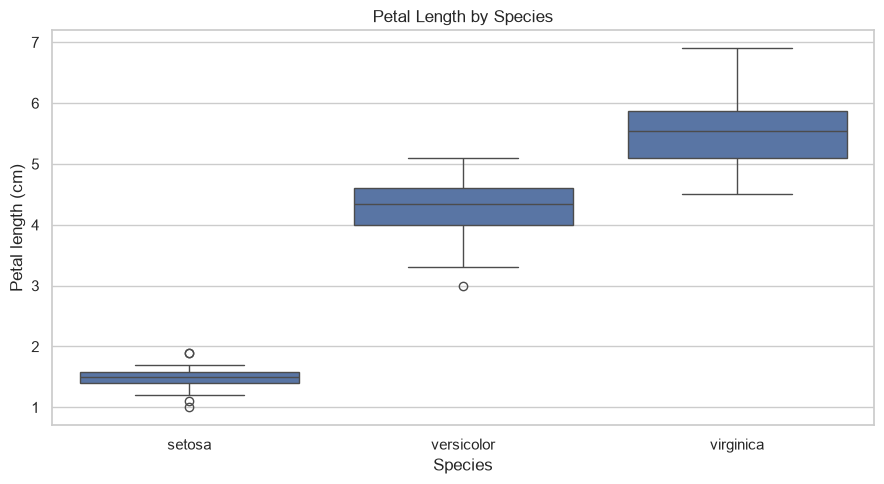

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species")
plt.title("Number of Samples per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="species", y="petal length (cm)")
plt.title("Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Petal length (cm)")
plt.tight_layout()
plt.show()

## 8. Relationship between petal length and petal width

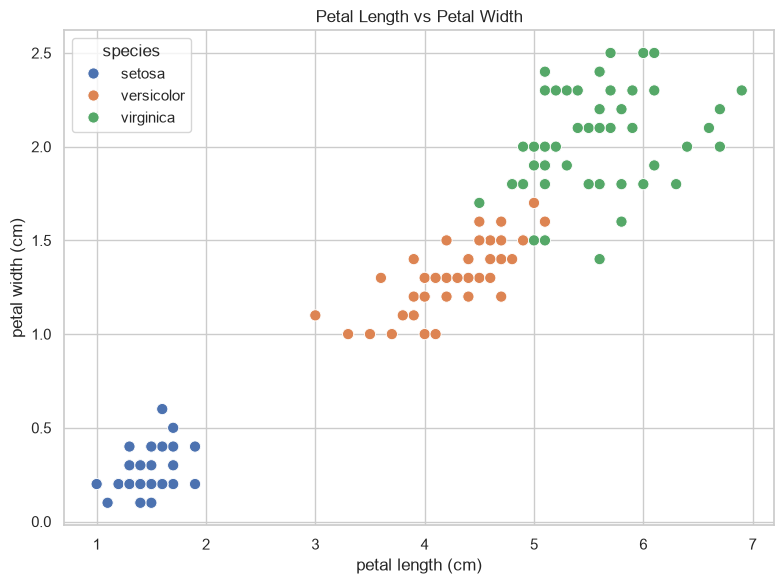

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=65
)
plt.title("Petal Length vs Petal Width")
plt.tight_layout()
plt.show()

**Observation:** Compare the clusters for each species. Petal measurements often provide clearer separation between species than sepal measurements.

## 9. Correlation analysis

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.12,0.87,0.82
sepal width (cm),-0.12,1.00,-0.43,-0.37
petal length (cm),0.87,-0.43,1.00,0.96
petal width (cm),0.82,-0.37,0.96,1.00


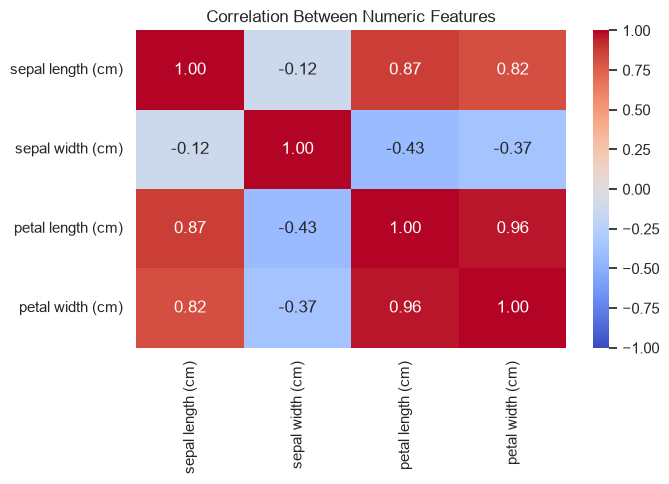

In [21]:
correlation = df[feature_columns].corr()
display(correlation.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

## 10. Train and evaluate a K-Nearest Neighbours classifier

Test accuracy: 0.933

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



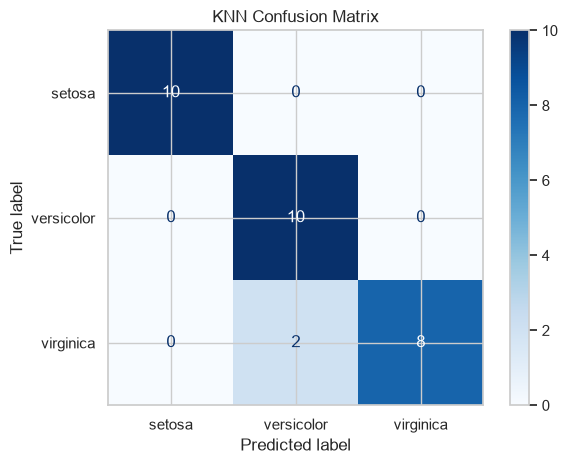

In [22]:
X = df[feature_columns]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=list(iris.target_names),
    display_labels=list(iris.target_names),
    cmap="Blues"
)
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:** Accuracy is the fraction of test examples classified correctly. Precision, recall, and F1-score describe performance by class. Use the confusion matrix to identify any classes the model confused. The result is based on one train/test split and is not a guarantee of future performance.

## 11. Predict a sample flower

In [23]:
sample_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=feature_columns
)
print("Sample flower measurements:")
display(sample_flower)
print("Predicted species:", model.predict(sample_flower)[0])

Sample flower measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted species: setosa


## 12. Summary and conclusion

In [24]:
print("DATASET SUMMARY")
print(f"Rows: {df.shape[0]}")
print(f"Numeric features: {len(feature_columns)}")
print("Species:", ", ".join(sorted(df["species"].unique())))
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print(f"KNN test accuracy: {accuracy:.3f}")

DATASET SUMMARY
Rows: 150
Numeric features: 4
Species: setosa, versicolor, virginica
Missing values: 0
Duplicate rows: 1
KNN test accuracy: 0.933


### Conclusion
This practical demonstrates a basic Data Science workflow. NumPy is used for numerical operations, Pandas for tabular data analysis, Matplotlib and Seaborn for visualization, and Scikit-learn for model training and evaluation. The notebook combines code, outputs, plots, and interpretation prompts in a reproducible format.
